# Семинар №5. Решение систем линейных алгебраических уравнений

## Подготовка к лабораторной работе №5

**Тема:** метод Гаусса, выбор ведущего элемента, LU-разложение и обусловленность.

На семинаре:

1. разберём прямой ход и обратную подстановку метода Гаусса;
2. интерактивно посмотрим, что меняет выбор ведущего элемента;
3. сравним **погрешность решения** и **невязку**;
4. исследуем матрицу Гильберта и число обусловленности;
5. разберём LU-разложение с перестановками строк: \(PA=LU\);
6. сравним решение многих систем методом Гаусса и через одно LU-разложение.

In [1]:
import time
import numpy as np
import matplotlib.pyplot as plt

np.set_printoptions(precision=5, suppress=True)
plt.rcParams["figure.figsize"] = (8, 5)
plt.rcParams["font.size"] = 11

try:
    from ipywidgets import interact, IntSlider, FloatSlider, Checkbox, Dropdown
    WIDGETS_AVAILABLE = True
except ImportError:
    WIDGETS_AVAILABLE = False
    print("ipywidgets недоступен: будут показаны статические примеры.")


ipywidgets недоступен: будут показаны статические примеры.


# 1. Что значит решить СЛАУ?

Система линейных алгебраических уравнений записывается в матричном виде:

$$
Ax=b,
$$

где \(A\) — матрица коэффициентов, \(x\) — неизвестный вектор, \(b\) — вектор правой части.

Если известно точное решение \(x^*\), то правую часть можно получить умножением:

$$
b=Ax^*.
$$

Это удобно для проверки алгоритма: мы заранее знаем, каким должен быть ответ.

## Первый пример

Рассмотрим систему из трёх уравнений. Сначала найдём решение встроенной функцией NumPy, а затем проверим, насколько хорошо оно удовлетворяет исходной системе.


In [2]:
A_demo = np.array([
    [2.0,  1.0, -1.0],
    [-3.0, -1.0, 2.0],
    [-2.0,  1.0, 2.0]
])
x_exact_demo = np.array([2.0, 3.0, -1.0])
b_demo = A_demo @ x_exact_demo

x_numpy = np.linalg.solve(A_demo, b_demo)
residual = A_demo @ x_numpy - b_demo

print("Матрица A:")
print(A_demo)
print("\nВектор b:")
print(b_demo)
print("\nТочное решение x*:")
print(x_exact_demo)
print("\nРешение np.linalg.solve:")
print(x_numpy)
print("\nНорма невязки ||Ax - b||₂:")
print(np.linalg.norm(residual))
print("\nНорма ошибки решения ||x - x*||₂:")
print(np.linalg.norm(x_numpy - x_exact_demo))


Матрица A:
[[ 2.  1. -1.]
 [-3. -1.  2.]
 [-2.  1.  2.]]

Вектор b:
[  8. -11.  -3.]

Точное решение x*:
[ 2.  3. -1.]

Решение np.linalg.solve:
[ 2.  3. -1.]

Норма невязки ||Ax - b||₂:
1.9860273225978185e-15

Норма ошибки решения ||x - x*||₂:
8.3820000221454525e-16


## Два разных показателя

**Ошибка решения** сравнивает найденный вектор с точным:

$$
e=x-x^*, \qquad
\varepsilon_{\mathrm{rel}}=
\frac{\|x-x^*\|_2}{\|x^*\|_2}.
$$

**Невязка** показывает, насколько найденный вектор удовлетворяет исходной системе:

$$
r=Ax-b, \qquad \|r\|_2.
$$

Ошибка решения требует знания точного ответа. Невязку можно вычислить, даже если точное решение неизвестно.

> Важно: малая невязка не всегда означает малую ошибку решения. Это станет особенно заметно на плохо обусловленных матрицах.


## Мини-задание 1

1. Почему в примере выше мы задаём \(b=A x^*\), а не выбираем \(b\) случайно?
2. Что проверяет величина \(\|Ax-b\|_2\)?
3. Можно ли вычислить ошибку \(\|x-x^*\|_2\), если точное решение \(x^*\) неизвестно?

<details>
<summary><b>Решение мини-задания 1</b></summary>

1. Так мы заранее знаем точное решение и можем объективно оценить ошибку алгоритма.
2. Она показывает, насколько найденный вектор удовлетворяет исходной системе.
3. Нет, для прямого вычисления ошибки нужно знать точное решение. Если оно неизвестно, используют невязку и другие оценки качества решения.
</details>


# 2. Метод Гаусса: прямой ход и обратная подстановка

Метод Гаусса состоит из двух этапов.

### Прямой ход

К расширенной матрице \([A\mid b]\) применяют преобразования строк, чтобы получить верхнетреугольную систему. На шаге \(k\) для строки \(i>k\) вычисляют множитель

$$
m_{ik}=\frac{a_{ik}}{a_{kk}},
$$

а затем выполняют преобразование

$$
R_i\leftarrow R_i-m_{ik}R_k.
$$

Так элемент под ведущим элементом \(a_{kk}\) становится нулём.

### Обратная подстановка

Когда система приведена к верхнетреугольному виду, неизвестные находят снизу вверх:

$$
x_i=\frac{b_i-\sum_{j=i+1}^{n}a_{ij}x_j}{a_{ii}}.
$$

Каждый шаг прямого хода устраняет одну неизвестную из строк ниже ведущей строки.


In [3]:
def back_substitution(U, b, tol=1e-14):
    """Решает Ux=b для верхнетреугольной матрицы U."""
    U = np.array(U, dtype=float, copy=True)
    b = np.array(b, dtype=float, copy=True).reshape(-1)

    n = U.shape[0]
    if U.shape != (n, n) or b.size != n:
        raise ValueError("Размеры U и b не согласованы.")

    x = np.zeros(n, dtype=float)
    for i in range(n - 1, -1, -1):
        if abs(U[i, i]) <= tol:
            raise np.linalg.LinAlgError("Нулевой или слишком малый диагональный элемент.")
        known_sum = U[i, i + 1:] @ x[i + 1:]
        x[i] = (b[i] - known_sum) / U[i, i]
    return x


def gaussian_solve(A, b, pivot=True, tol=1e-14):
    """
    Решает Ax=b методом Гаусса.
    pivot=True включает частичный выбор ведущего элемента.
    """
    A = np.array(A, dtype=float, copy=True)
    b = np.array(b, dtype=float, copy=True).reshape(-1)

    if A.ndim != 2 or A.shape[0] != A.shape[1]:
        raise ValueError("A должна быть квадратной матрицей.")
    n = A.shape[0]
    if b.size != n:
        raise ValueError("Размер b не согласован с A.")

    M = np.column_stack((A, b))

    for k in range(n - 1):
        if pivot:
            p = k + int(np.argmax(np.abs(M[k:, k])))
            if abs(M[p, k]) <= tol:
                raise np.linalg.LinAlgError("Матрица вырождена или ведущий элемент слишком мал.")
            if p != k:
                M[[k, p], :] = M[[p, k], :]
        elif abs(M[k, k]) <= tol:
            raise np.linalg.LinAlgError("Без перестановки получен нулевой или слишком малый ведущий элемент.")

        for i in range(k + 1, n):
            multiplier = M[i, k] / M[k, k]
            M[i, k:] -= multiplier * M[k, k:]
            M[i, k] = 0.0

    return back_substitution(M[:, :n], M[:, n], tol=tol)


## Посмотрим на прямой ход пошагово

В следующем примере можно переключать:

- **«Выбор ведущего элемента»** — использовать ли частичный выбор;
- **«Шаг»** — исходная расширенная матрица или результат очередного шага исключения.

При частичном выборе на каждом шаге в текущем столбце выбирается элемент с максимальным модулем среди строк, которые ещё не обработаны. При необходимости строки меняются местами.


После шага 2
Строки не переставляли: ведущий элемент уже максимален по модулю. Множители: m3,2=0.4002.
Последний столбец — правая часть b:
[[ 2.     -1.      1.     -1.    ]
 [ 0.      2.5    -1.5     6.5   ]
 [ 0.      0.      1.5998 -1.5998]]


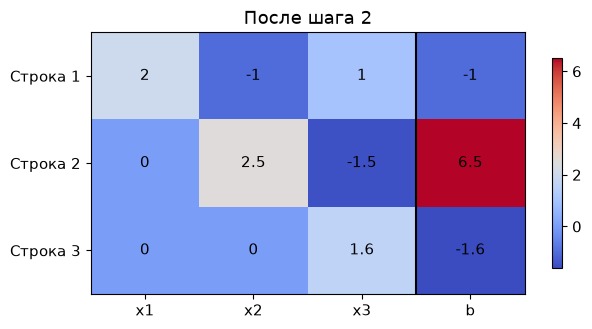

In [4]:
def gaussian_trace(A, b, pivot=True, tol=1e-14):
    A = np.array(A, dtype=float, copy=True)
    b = np.array(b, dtype=float, copy=True).reshape(-1)
    M = np.column_stack((A, b))
    n = A.shape[0]

    history = [("Исходная расширенная матрица", M.copy(),
                "Начинаем с матрицы [A|b].")]
    for k in range(n - 1):
        note = ""
        if pivot:
            p = k + int(np.argmax(np.abs(M[k:, k])))
            if abs(M[p, k]) <= tol:
                raise np.linalg.LinAlgError("Нулевой ведущий элемент.")
            if p != k:
                M[[k, p], :] = M[[p, k], :]
                note += f"Поменяли местами строки {k + 1} и {p + 1}. "
            else:
                note += "Строки не переставляли: ведущий элемент уже максимален по модулю. "
        else:
            if abs(M[k, k]) <= tol:
                raise np.linalg.LinAlgError("Без выбора ведущего элемента возник малый ведущий элемент.")
            note += "Перестановка строк отключена. "

        pivot_value = M[k, k]
        multipliers = []
        for i in range(k + 1, n):
            m = M[i, k] / pivot_value
            multipliers.append(f"m{i + 1},{k + 1}={m:.4g}")
            M[i, k:] -= m * M[k, k:]
            M[i, k] = 0.0

        note += "Множители: " + (", ".join(multipliers) if multipliers else "нет") + "."
        history.append((f"После шага {k + 1}", M.copy(), note))

    return history


A_trace = np.array([
    [1e-3, 1.0,  1.0],
    [1.0,  2.0, -1.0],
    [2.0, -1.0,  1.0]
])
x_trace_exact = np.array([1.0, 2.0, -1.0])
b_trace = A_trace @ x_trace_exact


def show_gauss_stage(stage=0, pivot=True):
    history = gaussian_trace(A_trace, b_trace, pivot=pivot, tol=1e-16)
    stage = min(stage, len(history) - 1)
    title, M, note = history[stage]

    print(title)
    print(note)
    print("Последний столбец — правая часть b:")
    print(M)

    fig, ax = plt.subplots(figsize=(7, 3.4))
    im = ax.imshow(M, cmap="coolwarm", aspect="auto")
    for i in range(M.shape[0]):
        for j in range(M.shape[1]):
            ax.text(j, i, f"{M[i, j]:.3g}", ha="center", va="center", fontsize=11)
    ax.set_xticks(range(M.shape[1]), [f"x{j+1}" for j in range(M.shape[1] - 1)] + ["b"])
    ax.set_yticks(range(M.shape[0]), [f"Строка {i+1}" for i in range(M.shape[0])])
    ax.set_title(title)
    ax.axvline(M.shape[1] - 1.5, color="black", linewidth=1.5)
    fig.colorbar(im, ax=ax, shrink=0.8)
    plt.show()


if WIDGETS_AVAILABLE:
    interact(
        show_gauss_stage,
        stage=IntSlider(min=0, max=2, step=1, value=0, description="Шаг"),
        pivot=Checkbox(value=True, description="Выбор ведущего")
    );
else:
    show_gauss_stage(stage=2, pivot=True)


## Мини-задание 2

Для системы, которая используется в интерактивном примере:

1. Найдите точное решение — оно задано в коде как `x_trace_exact`.
2. Посмотрите на первый шаг без выбора ведущего элемента.
3. Посмотрите на тот же шаг с выбором ведущего элемента.
4. Объясните, почему замена строки с ведущим элементом \(0{,}001\) на строку с элементом \(2\) меняет численную ситуацию.

<details>
<summary><b>Решение мини-задания 2</b></summary>

Точное решение — \(x^*=(1,2,-1)^T\). Без перестановки первым ведущим элементом становится \(0{,}001\), поэтому при исключении появляются большие множители. С частичным выбором ведущим элементом становится \(2\) по модулю: деление на очень маленькое число не требуется. Это обычно снижает влияние ошибок округления, хотя само по себе не гарантирует высокую точность для любой матрицы.
</details>


# 3. Выбор ведущего элемента: сравниваем два режима

Частичный выбор ведущего элемента означает, что на шаге \(k\) выбирают строку

$$
i^*=\arg\max_{i\geq k}|a_{ik}|
$$

и меняют её местами с текущей строкой \(k\).

Это защищает алгоритм от деления на ноль, если в столбце ниже есть ненулевой элемент, и часто уменьшает влияние округления.

Но важно различать два утверждения:

- **выбор ведущего элемента обычно улучшает устойчивость метода Гаусса;**
- **он не устраняет плохую обусловленность самой задачи.**


Без выбора
  x = [ 1.  2. -1.]
  Ошибка: 1.189631e-13
  Невязка: 2.821474e-13

С выбором
  x = [ 1.  2. -1.]
  Ошибка: 2.220446e-16
  Невязка: 3.140185e-16



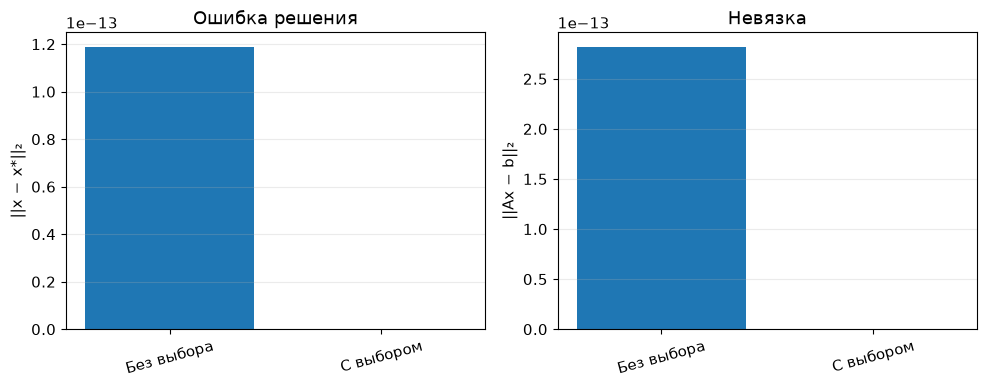

In [5]:
def compare_pivoting():
    results = []
    for use_pivot in [False, True]:
        x = gaussian_solve(A_trace, b_trace, pivot=use_pivot, tol=1e-16)
        results.append({
            "Режим": "С выбором" if use_pivot else "Без выбора",
            "x": x,
            "Ошибка ||x-x*||₂": np.linalg.norm(x - x_trace_exact),
            "Невязка ||Ax-b||₂": np.linalg.norm(A_trace @ x - b_trace)
        })

    for item in results:
        print(item["Режим"])
        print("  x =", item["x"])
        print(f'  Ошибка: {item["Ошибка ||x-x*||₂"]:.6e}')
        print(f'  Невязка: {item["Невязка ||Ax-b||₂"]:.6e}')
        print()

    labels = [r["Режим"] for r in results]
    errors = [r["Ошибка ||x-x*||₂"] for r in results]
    residuals = [r["Невязка ||Ax-b||₂"] for r in results]

    fig, axes = plt.subplots(1, 2, figsize=(10, 4))
    axes[0].bar(labels, errors)
    axes[0].set_title("Ошибка решения")
    axes[0].set_ylabel("||x − x*||₂")
    axes[1].bar(labels, residuals)
    axes[1].set_title("Невязка")
    axes[1].set_ylabel("||Ax − b||₂")
    for ax in axes:
        ax.tick_params(axis="x", rotation=15)
        ax.grid(axis="y", alpha=0.25)
    plt.tight_layout()
    plt.show()


compare_pivoting()


## Мини-задание 3

Почему нельзя утверждать, что метод без выбора ведущего элемента всегда даст неправильный ответ? И почему нельзя утверждать, что частичный выбор гарантирует точный ответ?

<details>
<summary><b>Решение мини-задания 3</b></summary>

Если ведущие элементы достаточно велики и матрица хорошо обусловлена, метод без перестановок может дать хороший результат. Частичный выбор уменьшает риск, связанный с малыми ведущими элементами, но не меняет число обусловленности матрицы и не устраняет все ошибки округления.
</details>


# 4. Ошибка и невязка

В исходном задании предлагается сравнить ошибку решения и невязку для обычной матрицы и матрицы Гильберта \(H_8\).

Матрица Гильберта задаётся формулой

$$
(H_n)_{ij}=\frac{1}{i+j-1}, \qquad i,j=1,\ldots,n.
$$

Для неё зададим точное решение \(x^*=(1,\ldots,1)^T\), а затем построим правую часть \(b=H_nx^*\).

**Задание:** запустите эксперимент, сравните числа и объясните, почему малая невязка не обязательно означает малую ошибку решения.


In [6]:
def hilbert_matrix(n):
    i = np.arange(1, n + 1, dtype=float)
    return 1.0 / (i[:, None] + i[None, :] - 1.0)


def compare_error_and_residual(A, x_exact, label):
    b = A @ x_exact
    print(f"\n{label}")
    print(f"Число обусловленности κ₂(A): {np.linalg.cond(A):.6e}")
    print(f"{'Режим':<20} {'Относительная ошибка':>24} {'Невязка':>16}")
    for pivot in [False, True]:
        try:
            x = gaussian_solve(A, b, pivot=pivot, tol=0.0)
            rel_error = np.linalg.norm(x - x_exact) / np.linalg.norm(x_exact)
            residual_norm = np.linalg.norm(A @ x - b)
            name = "Без выбора" if not pivot else "С частичным выбором"
            print(f"{name:<20} {rel_error:>24.6e} {residual_norm:>16.6e}")
        except np.linalg.LinAlgError as exc:
            name = "Без выбора" if not pivot else "С частичным выбором"
            print(f"{name:<20} ошибка алгоритма: {exc}")


A_regular = np.array([
    [4.0, 1.0, 0.0],
    [1.0, 3.0, 1.0],
    [0.0, 1.0, 2.0]
])
x_regular_exact = np.array([1.0, 1.0, 1.0])

compare_error_and_residual(A_regular, x_regular_exact, "Обычная хорошо обусловленная матрица")

H8 = hilbert_matrix(8)
x_H8_exact = np.ones(8)
compare_error_and_residual(H8, x_H8_exact, "Матрица Гильберта H₈")



Обычная хорошо обусловленная матрица
Число обусловленности κ₂(A): 3.732051e+00
Режим                    Относительная ошибка          Невязка
Без выбора                       0.000000e+00     0.000000e+00
С частичным выбором              0.000000e+00     0.000000e+00

Матрица Гильберта H₈
Число обусловленности κ₂(A): 1.525758e+10
Режим                    Относительная ошибка          Невязка
Без выбора                       1.500725e-07     4.002966e-16
С частичным выбором              3.585112e-08     1.110223e-16


## Как интерпретировать эксперимент?

Обратите внимание не только на невязку, но и на число обусловленности \(\kappa(A)\).

- У обычной хорошо обусловленной матрицы ошибка решения обычно мала.
- У матрицы Гильберта число обусловленности значительно больше: небольшие ошибки вычислений могут заметно изменить найденный вектор.
- Невязка при этом может оставаться очень маленькой.

<details>
<summary><b>Ожидаемый вывод</b></summary>

Для матрицы Гильберта малая невязка не гарантирует близость найденного решения к точному. Причина — плохая обусловленность: вычислительные ошибки могут сильно влиять на решение, даже если вычисленный вектор почти удовлетворяет системе. Частичный выбор ведущего элемента может улучшить результат, но не устраняет плохую обусловленность.
</details>


# 5. Число обусловленности и матрица Гильберта

Число обусловленности в выбранной норме:

$$
\kappa(A)=\|A\|\,\|A^{-1}\|.
$$

Оно характеризует чувствительность решения к небольшим изменениям исходных данных. Чем больше \(\kappa(A)\), тем сильнее малые возмущения коэффициентов или правой части могут повлиять на результат.

В лабораторной работе требуется исследовать матрицы Гильберта размерностей \(n=5,10,12,15\), для которых точное решение задаётся вектором из единиц.

Для учебного эксперимента ниже допускается продолжить вычисления при очень малых ненулевых ведущих элементах (`tol=0.0`). Это сделано, чтобы увидеть ухудшение численного результата; в прикладном коде такой порог нельзя использовать как универсальную проверку надёжности.


  n          κ₂(Hₙ)    Ошибка без выбора     Ошибка с выбором
  5      4.7661e+05           1.5530e-12           3.4934e-13
 10      1.6025e+13           4.5940e-05           8.2423e-05
 12      1.8078e+16           1.9825e-01           2.4280e-01
 15      8.7184e+17           4.3321e+00           4.0947e+00


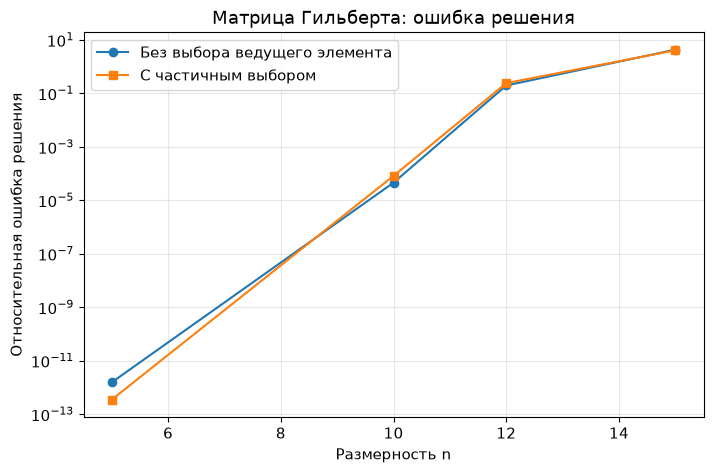

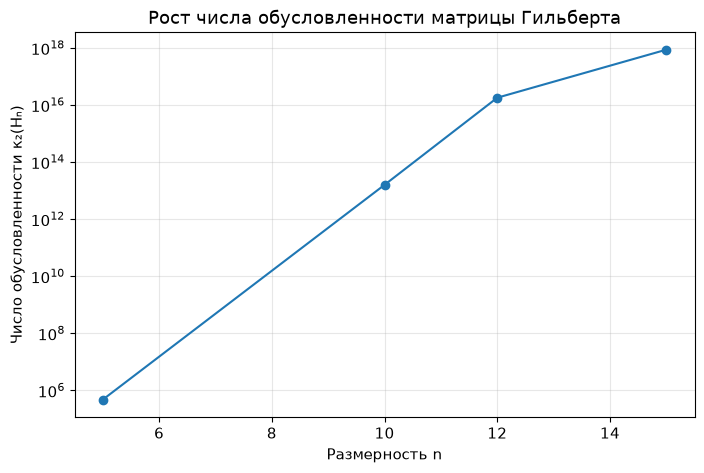

In [7]:
hilbert_sizes = [5, 10, 12, 15]
hilbert_results = []

for n in hilbert_sizes:
    H = hilbert_matrix(n)
    x_star = np.ones(n)
    b = H @ x_star
    row = {
        "n": n,
        "cond": np.linalg.cond(H),
        "err_no_pivot": np.nan,
        "err_pivot": np.nan,
        "res_no_pivot": np.nan,
        "res_pivot": np.nan
    }

    for pivot in [False, True]:
        try:
            x = gaussian_solve(H, b, pivot=pivot, tol=0.0)
            rel_error = np.linalg.norm(x - x_star) / np.linalg.norm(x_star)
            residual_norm = np.linalg.norm(H @ x - b)
            if pivot:
                row["err_pivot"] = rel_error
                row["res_pivot"] = residual_norm
            else:
                row["err_no_pivot"] = rel_error
                row["res_no_pivot"] = residual_norm
        except np.linalg.LinAlgError:
            pass

    hilbert_results.append(row)

print(f"{'n':>3} {'κ₂(Hₙ)':>15} {'Ошибка без выбора':>20} {'Ошибка с выбором':>20}")
for row in hilbert_results:
    print(f"{row['n']:>3} {row['cond']:>15.4e} "
          f"{row['err_no_pivot']:>20.4e} {row['err_pivot']:>20.4e}")

plt.figure(figsize=(8, 5))
plt.semilogy(
    hilbert_sizes,
    [row["err_no_pivot"] for row in hilbert_results],
    "o-", label="Без выбора ведущего элемента"
)
plt.semilogy(
    hilbert_sizes,
    [row["err_pivot"] for row in hilbert_results],
    "s-", label="С частичным выбором"
)
plt.xlabel("Размерность n")
plt.ylabel("Относительная ошибка решения")
plt.title("Матрица Гильберта: ошибка решения")
plt.grid(True, which="both", alpha=0.3)
plt.legend()
plt.show()

plt.figure(figsize=(8, 5))
plt.semilogy(hilbert_sizes, [row["cond"] for row in hilbert_results], "o-")
plt.xlabel("Размерность n")
plt.ylabel("Число обусловленности κ₂(Hₙ)")
plt.title("Рост числа обусловленности матрицы Гильберта")
plt.grid(True, which="both", alpha=0.3)
plt.show()


## Интерактивный исследовательский вопрос

Меняйте размерность матрицы Гильберта и включайте/выключайте частичный выбор ведущего элемента. На графике сравниваются точное решение из единиц и численно найденные компоненты.

Постарайтесь заметить, при какой размерности компоненты найденного решения начинают заметно отклоняться от единицы.


Размерность n = 8
κ₂(Hₙ) = 1.525758e+10
Относительная ошибка = 3.585112e-08
Невязка = 1.110223e-16


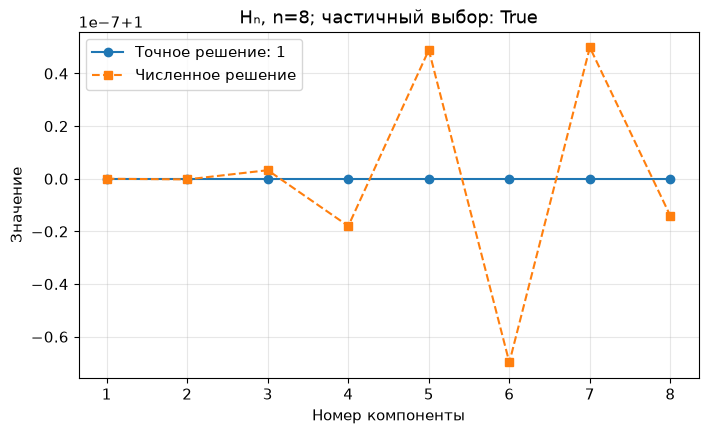

In [8]:
def show_hilbert_solution(n=8, pivot=True):
    H = hilbert_matrix(n)
    x_star = np.ones(n)
    b = H @ x_star

    try:
        x = gaussian_solve(H, b, pivot=pivot, tol=0.0)
        rel_error = np.linalg.norm(x - x_star) / np.linalg.norm(x_star)
        residual_norm = np.linalg.norm(H @ x - b)

        print(f"Размерность n = {n}")
        print(f"κ₂(Hₙ) = {np.linalg.cond(H):.6e}")
        print(f"Относительная ошибка = {rel_error:.6e}")
        print(f"Невязка = {residual_norm:.6e}")

        plt.figure(figsize=(8, 4.5))
        plt.plot(np.arange(1, n + 1), x_star, "o-", label="Точное решение: 1")
        plt.plot(np.arange(1, n + 1), x, "s--", label="Численное решение")
        plt.xlabel("Номер компоненты")
        plt.ylabel("Значение")
        plt.title(f"Hₙ, n={n}; частичный выбор: {pivot}")
        plt.grid(True, alpha=0.3)
        plt.legend()
        plt.show()
    except np.linalg.LinAlgError as exc:
        print("Решатель остановлен:", exc)


if WIDGETS_AVAILABLE:
    interact(
        show_hilbert_solution,
        n=IntSlider(min=2, max=15, step=1, value=8, description="Размер n"),
        pivot=Checkbox(value=True, description="Частичный выбор")
    );
else:
    show_hilbert_solution(n=8, pivot=True)


## Мини-задание 4

1. Почему число обусловленности растёт с размерностью матрицы Гильберта?
2. Всегда ли частичный выбор ведущего элемента даёт меньшую ошибку на каждом отдельном примере?
3. Как связаны число обусловленности и надёжность вычисленного решения?

<details>
<summary><b>Решение мини-задания 4</b></summary>

1. Матрица Гильберта становится всё более плохо обусловленной при увеличении размерности.
2. Нет. Частичный выбор часто улучшает устойчивость, но не гарантирует строго меньшую ошибку в каждом эксперименте.
3. Чем больше число обусловленности, тем сильнее решение может реагировать на малые ошибки входных данных и округления.
</details>


# 6. LU-разложение: зачем нужны три матрицы?

При LU-разложении матрицу представляют как произведение нижнетреугольной \(L\) и верхнетреугольной \(U\). Если во время исключения переставляются строки, используется запись

$$
PA=LU,
$$

где \(P\) — матрица перестановок.

После разложения исходная система \(Ax=b\) решается в два этапа:

$$
Ly=Pb,\qquad Ux=y.
$$

То есть:

1. один раз строим \(P,L,U\);
2. решаем нижнетреугольную систему для \(y\);
3. решаем верхнетреугольную систему для \(x\).

**Почему это полезно?** Если матрица \(A\) одна и та же, а векторы правой части разные, разложение можно переиспользовать.


In [9]:
def forward_substitution(L, b, tol=1e-14):
    """Решает Ly=b для нижнетреугольной матрицы L."""
    L = np.array(L, dtype=float, copy=True)
    b = np.array(b, dtype=float, copy=True).reshape(-1)
    n = L.shape[0]

    if L.shape != (n, n) or b.size != n:
        raise ValueError("Размеры L и b не согласованы.")

    y = np.zeros(n, dtype=float)
    for i in range(n):
        if abs(L[i, i]) <= tol:
            raise np.linalg.LinAlgError("Нулевой диагональный элемент L.")
        known_sum = L[i, :i] @ y[:i]
        y[i] = (b[i] - known_sum) / L[i, i]
    return y


def lu_decomposition(A, tol=1e-14):
    """
    LU-разложение с частичным выбором ведущего элемента.
    Возвращает P, L, U, такие что P @ A ≈ L @ U.
    """
    A = np.array(A, dtype=float, copy=True)
    if A.ndim != 2 or A.shape[0] != A.shape[1]:
        raise ValueError("A должна быть квадратной матрицей.")

    n = A.shape[0]
    U = A.copy()
    L = np.eye(n)
    P = np.eye(n)

    for k in range(n):
        p = k + int(np.argmax(np.abs(U[k:, k])))
        if abs(U[p, k]) <= tol:
            raise np.linalg.LinAlgError("Матрица вырождена или ведущий элемент слишком мал.")

        if p != k:
            U[[k, p], :] = U[[p, k], :]
            P[[k, p], :] = P[[p, k], :]
            if k > 0:
                L[[k, p], :k] = L[[p, k], :k]

        for i in range(k + 1, n):
            L[i, k] = U[i, k] / U[k, k]
            U[i, k:] -= L[i, k] * U[k, k:]
            U[i, k] = 0.0

    return P, L, U


def lu_solve(P, L, U, b, tol=1e-14):
    """Решает Ax=b по разложению P@A=L@U."""
    b = np.array(b, dtype=float, copy=True).reshape(-1)
    y = forward_substitution(L, P @ b, tol=tol)
    x = back_substitution(U, y, tol=tol)
    return x


## Проверяем, что разложение корректно

Для корректной реализации должно выполняться

$$
\|PA-LU\|\approx 0.
$$

Не требуется, чтобы все элементы разности были абсолютно равны нулю: вычисления с плавающей точкой дают небольшие ошибки округления.


In [10]:
P_demo, L_demo, U_demo = lu_decomposition(A_demo)

print("P =")
print(P_demo)
print("\nL =")
print(L_demo)
print("\nU =")
print(U_demo)
print("\nP @ A =")
print(P_demo @ A_demo)
print("\nL @ U =")
print(L_demo @ U_demo)
print("\n||P A - L U||₂ =")
print(np.linalg.norm(P_demo @ A_demo - L_demo @ U_demo))

x_lu_demo = lu_solve(P_demo, L_demo, U_demo, b_demo)
print("\nРешение через LU:", x_lu_demo)
print("Невязка решения через LU:", np.linalg.norm(A_demo @ x_lu_demo - b_demo))


P =
[[0. 1. 0.]
 [0. 0. 1.]
 [1. 0. 0.]]

L =
[[ 1.       0.       0.     ]
 [ 0.66667  1.       0.     ]
 [-0.66667  0.2      1.     ]]

U =
[[-3.      -1.       2.     ]
 [ 0.       1.66667  0.66667]
 [ 0.       0.       0.2    ]]

P @ A =
[[-3. -1.  2.]
 [-2.  1.  2.]
 [ 2.  1. -1.]]

L @ U =
[[-3. -1.  2.]
 [-2.  1.  2.]
 [ 2.  1. -1.]]

||P A - L U||₂ =
1.1102230246251565e-16

Решение через LU: [ 2.  3. -1.]
Невязка решения через LU: 4.440892098500626e-16


## Интерактивный просмотр \(P\), \(L\), \(U\)

Выберите матрицу, чтобы увидеть её структуру. Матрица \(P\) отражает перестановки строк, \(L\) содержит множители прямого хода, а \(U\) — полученную верхнетреугольную матрицу.


P:
[[0. 1. 0.]
 [0. 0. 1.]
 [1. 0. 0.]]


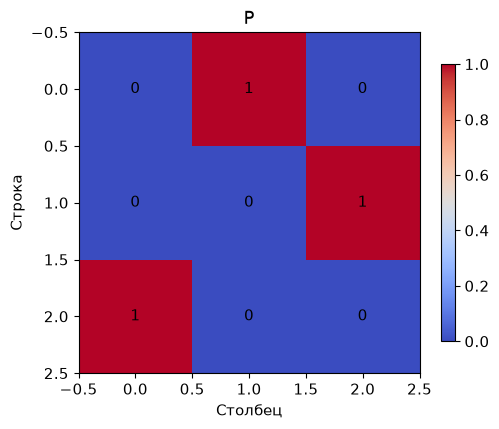

In [11]:
def show_lu_matrix(part="P"):
    A = A_demo
    P, L, U = lu_decomposition(A)
    matrices = {
        "P": P,
        "L": L,
        "U": U,
        "P @ A − L @ U": P @ A - L @ U
    }
    M = matrices[part]

    print(f"{part}:")
    print(M)

    fig, ax = plt.subplots(figsize=(5.5, 4.5))
    im = ax.imshow(M, cmap="coolwarm", aspect="equal")
    for i in range(M.shape[0]):
        for j in range(M.shape[1]):
            ax.text(j, i, f"{M[i, j]:.3g}", ha="center", va="center")
    ax.set_title(part)
    ax.set_xlabel("Столбец")
    ax.set_ylabel("Строка")
    fig.colorbar(im, ax=ax, shrink=0.8)
    plt.show()


if WIDGETS_AVAILABLE:
    interact(
        show_lu_matrix,
        part=Dropdown(
            options=["P", "L", "U", "P @ A − L @ U"],
            value="P",
            description="Матрица"
        )
    );
else:
    show_lu_matrix("P")


## Мини-задание 5

1. Почему при использовании \(PA=LU\) правая часть в первой треугольной системе равна \(Pb\), а не \(b\)?
2. Почему при перестановке строк \(U\) нужно переставлять соответствующие уже заполненные элементы строк \(L\)?
3. Что означает малая величина \(\|PA-LU\|\)?

<details>
<summary><b>Решение мини-задания 5</b></summary>

1. Из \(PA=LU\) и \(Ax=b\) следует \(LUx=Pb\). Поэтому сначала решается \(Ly=Pb\).
2. Элементы \(L\) в уже обработанных столбцах хранят множители предыдущих шагов. При перестановке строк эти множители должны остаться связанными с соответствующими строками.
3. Она показывает, что произведение полученных матриц \(L\) и \(U\) близко к \(PA\), то есть разложение реализовано корректно с точностью до округления.
</details>


# 7. Почему LU выгодно при многих правых частях?

Пусть нужно решить системы

$$
Ax=b_1,\quad Ax=b_2,\quad \ldots,\quad Ax=b_k
$$

с одной и той же матрицей \(A\).

- При повторном применении метода Гаусса прямой ход фактически выполняется заново для каждой правой части.
- При LU-разложении факторизация выполняется один раз, после чего для каждой новой правой части остаются две треугольные подстановки.

Оценки вычислительной сложности:

- факторизация: \(O(n^3)\);
- решение одной системы после факторизации: \(O(n^2)\).

Следующий эксперимент измеряет время для разных количеств правых частей. Замеры на небольших задачах зависят от компьютера и фоновой нагрузки, поэтому важнее общая тенденция, а не конкретные миллисекунды.


Размер матрицы: 45 × 45
Количество правых частей: 30
Метод Гаусса, все решения: 0.054622 с
LU-факторизация: 0.002421 с
Все треугольные решения: 0.003647 с
LU всего: 0.006068 с
Отношение времени Гаусс / LU: 9.002
Максимальное различие решений: 3.469e-17


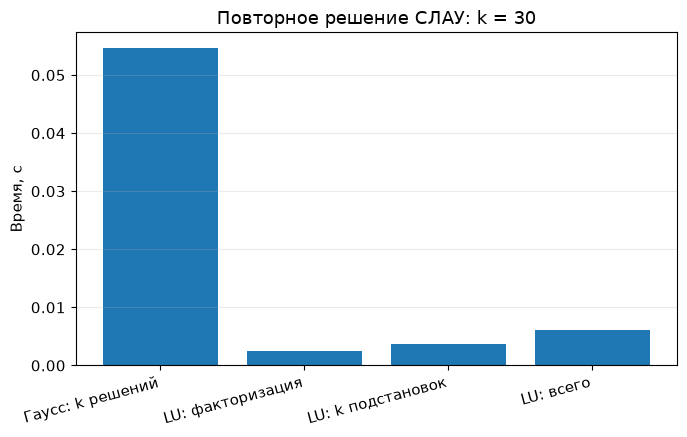

In [12]:
def compare_many_rhs(k=20):
    rng = np.random.default_rng(2026)
    n = 45
    A = rng.normal(size=(n, n)) + n * np.eye(n)
    B = rng.normal(size=(n, k))

    # Метод Гаусса: решение каждой системы с нуля.
    t0 = time.perf_counter()
    X_gauss = np.column_stack([
        gaussian_solve(A, B[:, j], pivot=True, tol=1e-14)
        for j in range(k)
    ])
    t_gauss = time.perf_counter() - t0

    # LU: факторизация один раз.
    t0 = time.perf_counter()
    P, L, U = lu_decomposition(A, tol=1e-14)
    t_factor = time.perf_counter() - t0

    t0 = time.perf_counter()
    X_lu = np.column_stack([
        lu_solve(P, L, U, B[:, j], tol=1e-14)
        for j in range(k)
    ])
    t_triangular = time.perf_counter() - t0

    t_lu_total = t_factor + t_triangular
    speedup = t_gauss / t_lu_total if t_lu_total > 0 else np.nan
    max_difference = np.max(np.abs(X_gauss - X_lu))

    print(f"Размер матрицы: {n} × {n}")
    print(f"Количество правых частей: {k}")
    print(f"Метод Гаусса, все решения: {t_gauss:.6f} с")
    print(f"LU-факторизация: {t_factor:.6f} с")
    print(f"Все треугольные решения: {t_triangular:.6f} с")
    print(f"LU всего: {t_lu_total:.6f} с")
    print(f"Отношение времени Гаусс / LU: {speedup:.3f}")
    print(f"Максимальное различие решений: {max_difference:.3e}")

    plt.figure(figsize=(7, 4.5))
    plt.bar(
        ["Гаусс: k решений", "LU: факторизация", "LU: k подстановок", "LU: всего"],
        [t_gauss, t_factor, t_triangular, t_lu_total]
    )
    plt.ylabel("Время, с")
    plt.title(f"Повторное решение СЛАУ: k = {k}")
    plt.xticks(rotation=15, ha="right")
    plt.grid(axis="y", alpha=0.25)
    plt.tight_layout()
    plt.show()


if WIDGETS_AVAILABLE:
    interact(
        compare_many_rhs,
        k=IntSlider(min=1, max=100, step=1, value=20, description="Число b")
    );
else:
    compare_many_rhs(k=30)


## Мини-задание 6

1. Почему LU-разложение может оказаться медленнее метода Гаусса, если нужно решить только одну систему?
2. Что именно переиспользуется при переходе от \(b_1\) к \(b_2\)?
3. Почему при росте числа правых частей преимущество LU обычно становится заметнее?

<details>
<summary><b>Решение мини-задания 6</b></summary>

1. Для LU требуется сначала выполнить факторизацию, а затем треугольные подстановки. Для одной системы факторизация не убирает основную кубическую часть вычислений.
2. Переиспользуются матрицы \(P\), \(L\) и \(U\); заново выполняются только решения \(Ly=Pb\) и \(Ux=y\).
3. Стоимость факторизации распределяется на большее число систем, а каждая новая система требует только \(O(n^2)\) операций.
</details>


# 8. Вопросы для обсуждения

Попробуйте ответить без запуска кода.

1. Как определить, что матрица вырождена?
2. Зачем нужен частичный выбор ведущего элемента?
3. Чем ошибка решения отличается от невязки?
4. Почему у матрицы Гильберта может быть малая невязка и заметная ошибка решения?
5. Что означает число обусловленности \(\kappa(A)\)?
6. Почему при перестановках строк используется \(PA=LU\), а не обязательно \(A=LU\)?
7. Почему LU-разложение удобно при многих правых частях?
8. Какова асимптотическая сложность метода Гаусса и LU-факторизации?
9. Какие проверки помогают понять, что собственная реализация работает корректно?
10. Почему нельзя делать вывод о скорости метода по одному небольшому замеру?


# Мини-шпаргалка

### Метод Гаусса

$$
m_{ik}=\frac{a_{ik}}{a_{kk}},\qquad
R_i\leftarrow R_i-m_{ik}R_k.
$$

Частичный выбор:

$$
i^*=\arg\max_{i\ge k}|a_{ik}|.
$$

### Проверка решения

$$
r=Ax-b,\qquad
\varepsilon_{\mathrm{rel}}=\frac{\|x-x^*\|_2}{\|x^*\|_2}.
$$

### Обусловленность

$$
\kappa(A)=\|A\|\,\|A^{-1}\|.
$$

### LU с перестановками

$$
PA=LU,\qquad Ly=Pb,\qquad Ux=y.
$$

### Вычислительная сложность

- Факторизация: \(O(n^3)\).
- Треугольные подстановки для одной правой части: \(O(n^2)\).

**Главная идея семинара:** корректность вычислений, точность решения и скорость алгоритма — разные характеристики. Их нужно проверять отдельно.
